# CDC PTB · абляции групп признаков

## tl;dr

Для выбранного в 02 типа модели по одному удаляются анамнез преждевременных родов, вся акушерская история, BMI, хронические состояния и курение до беременности. В проверенном прогоне удаление всей акушерской истории увеличило log loss на **0,00710**. Каждый вариант заново обучается на тех же строках 2023 года и оценивается на том же validation.

## Контекст и методы

Абляция показывает изменение качества **прогноза** при удалении информации, а не причинное влияние признака. Маска пропуска удаляется вместе со своим полем. Параметры типа модели зафиксированы по 02; нового выбора по абляциям не делаем.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .16})
BLUE, ORANGE, GOLD, SLATE = "#28628A", "#BA6234", "#B78918", "#3B4855"
from src.training.preterm_cdc import run_ablations

## Результаты

In [4]:
ablations = run_ablations()
cols = ["ablation", "removed", "n", "multiclass_log_loss", "delta_log_loss_vs_full", "auprc_lt32", "auprc_lt37"]
display(ablations[cols].round(5))

,ablation,removed,n,multiclass_log_loss,delta_log_loss_vs_full,auprc_lt32,auprc_lt37
0,full,NaN,200000,0.34729,0.00000,0.03455,0.17225
1,without_previous_ptb,previous_preterm_birth,200000,0.35188,0.00459,0.02805,0.14810
2,without_obstetric_history,"previous_live_births, previous_terminations, p...",200000,0.35439,0.00710,0.02366,0.13756
3,without_bmi,prepregnancy_bmi,200000,0.34864,0.00135,0.03145,0.16591
4,without_chronic_conditions,"chronic_hypertension, preexisting_diabetes",200000,0.34955,0.00225,0.03061,0.15883
5,without_smoking,prepregnancy_cigarettes_per_day,200000,0.34780,0.00051,0.03374,0.17035


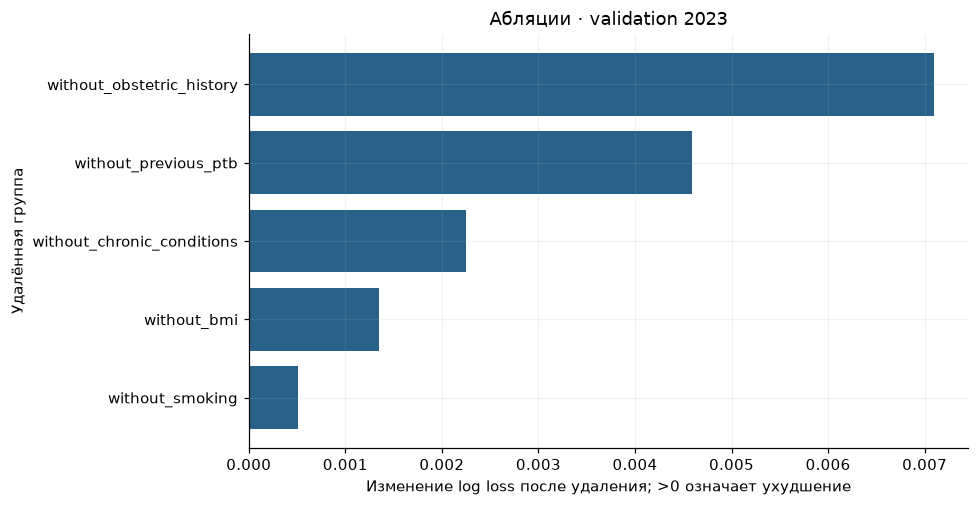

In [5]:
plot = ablations.loc[ablations.ablation.ne("full")].sort_values("delta_log_loss_vs_full")
fig, ax = plt.subplots(figsize=(9, 4.7))
ax.barh(plot.ablation, plot.delta_log_loss_vs_full, color=BLUE)
ax.axvline(0, color=SLATE, linewidth=1)
ax.set(xlabel="Изменение log loss после удаления; >0 означает ухудшение", ylabel="Удалённая группа", title="Абляции · validation 2023")
plt.tight_layout(); plt.show()

## Выводы

Validation уже использовалась при подборе модели; эти различия служат диагностикой, без доверительного интервала и без независимого утверждения о пользе поля. Взаимосвязанные признаки способны частично заменять друг друга.